# Observations and output sites

Define the onshore wave observations available for your case (buoys, tide gauges, spectral sites, ...), preview them on a map, and save a **JSON (GeoJSON format)** file compatible with QGIS and the HyGloW config loader.

Workflow:

1. Set the output file name/path in the parameters cell.
2. Edit the `observations` dict below (one entry per instrument).
3. Run the preview cells to check table and map.
4. Save the JSON to disk.
5. Add/update `"onshore_waves"` in the case JSON with the saved file path.
6. Build the output sites on the model mesh (isobaths + buoys) and check
   their mesh depths: the metamodel and dynamic runs use this table.

In [1]:
from utils.config import PATHS, resolve
from utils import onshore_sites as obs
from utils import viz as plot

## Parameters

In [2]:
from utils.config import ONSHORE_WAVES

# Output file — defaults to the path declared in the case config ("onshore_waves").
output_observations_file = ONSHORE_WAVES
output_path = resolve(output_observations_file)

print(f"output   : {output_path}")
print(f"AoI      : {resolve(PATHS['aoi_file'])}")
print(f"topobathy: {resolve(PATHS['topobathy_file'])}")

output   : /lustre/geocean/WORK/users/javiert/projects/HyGloW/NorthCarolina/inputs/Observations/NorthCarolina_observations.json
AoI      : /lustre/geocean/WORK/users/javiert/projects/HyGloW/NorthCarolina/inputs/AoI_Polygons/NorthCarolina_AoI.shp
topobathy: /lustre/geocean/WORK/users/javiert/projects/HyGloW/NorthCarolina/inputs/Bathymetry/NorthCarolina_topobathy_3s.tiff


## Observations dict

NDBC stations inside the mesh with at least half a year of waves (positions and
water depths from the NDBC station pages, 2026-11-15; `null` where the page gives
none). Ten of them are CDIP buoys. `station` is the NDBC id of the record.

41025 Diamond Shoals has been moored at more than one position: the current one
is used.

In [3]:
observations: dict[str, dict] = {
    "NDBC_41013": {"station": "41013", "lon": -77.764, "lat": 33.436, "type": "waves", "institution": "NDBC", "recording": "2003-2024", "measured_depth": 30.8, "name": "Frying Pan Shoals"},
    "NDBC_41025": {"station": "41025", "lon": -75.38, "lat": 35.026, "type": "waves", "institution": "NDBC", "recording": "2003-2024", "measured_depth": 61.0, "name": "Diamond Shoals"},
    "NDBC_41035": {"station": "41035", "lon": -77.28, "lat": 34.476, "type": "waves", "institution": "NDBC", "recording": "2005-2010", "measured_depth": 9.7, "name": "Onslow Bay Inner"},
    "NDBC_41036": {"station": "41036", "lon": -76.949, "lat": 34.207, "type": "waves", "institution": "NDBC", "recording": "2006-2015", "measured_depth": None, "name": "Onslow Bay Outer"},
    "NDBC_41108": {"station": "41108", "lon": -78.016, "lat": 33.719, "type": "waves", "institution": "CDIP / NDBC", "recording": "2013-2024", "measured_depth": 12.8, "name": "Wilmington Harbor (CDIP 200)"},
    "NDBC_41109": {"station": "41109", "lon": -77.3, "lat": 34.484, "type": "waves", "institution": "CDIP / NDBC", "recording": "2012-2013", "measured_depth": 13.2, "name": "New River Inlet (CDIP 190)"},
    "NDBC_41110": {"station": "41110", "lon": -77.715, "lat": 34.144, "type": "waves", "institution": "CDIP / NDBC", "recording": "2008-2024", "measured_depth": 17.0, "name": "Masonboro Inlet (CDIP 150)"},
    "NDBC_41119": {"station": "41119", "lon": -78.483, "lat": 33.842, "type": "waves", "institution": "CDIP / NDBC", "recording": "2019", "measured_depth": 13.0, "name": "Sunset Beach (CDIP 245)"},
    "NDBC_41120": {"station": "41120", "lon": -75.285, "lat": 35.258, "type": "waves", "institution": "CDIP / NDBC", "recording": "2021-2024", "measured_depth": 29.0, "name": "Cape Hatteras East (CDIP 250)"},
    "NDBC_41159": {"station": "41159", "lon": -76.944, "lat": 34.211, "type": "waves", "institution": "CDIP / NDBC", "recording": "2015-2024", "measured_depth": 30.5, "name": "Onslow Bay Outer (CDIP 217)"},
    "NDBC_44014": {"station": "44014", "lon": -74.837, "lat": 36.603, "type": "waves", "institution": "NDBC", "recording": "1990-2024", "measured_depth": 49.1, "name": "Virginia Beach, 64 NM east"},
    "NDBC_44056": {"station": "44056", "lon": -75.714, "lat": 36.2, "type": "waves", "institution": "USACE / NDBC", "recording": "2012-2024", "measured_depth": 17.8, "name": "Duck FRF 17 m"},
    "NDBC_44086": {"station": "44086", "lon": -75.421, "lat": 36.001, "type": "waves", "institution": "CDIP / NDBC", "recording": "2018-2024", "measured_depth": 21.0, "name": "Nags Head (CDIP 243)"},
    "NDBC_44088": {"station": "44088", "lon": -74.839, "lat": 36.612, "type": "waves", "institution": "CDIP / NDBC", "recording": "2017-2024", "measured_depth": 45.7, "name": "Virginia Beach Offshore (CDIP 171)"},
    "NDBC_44095": {"station": "44095", "lon": -75.33, "lat": 35.75, "type": "waves", "institution": "CDIP / NDBC", "recording": "2013-2024", "measured_depth": 18.3, "name": "Oregon Inlet (CDIP 192)"},
    "NDBC_44100": {"station": "44100", "lon": -75.593, "lat": 36.257, "type": "waves", "institution": "CDIP / NDBC", "recording": "2008-2024", "measured_depth": 25.0, "name": "Duck FRF 26 m (CDIP 430)"},
    "NDBC_dsln7": {"station": "dsln7", "lon": -75.297, "lat": 35.153, "type": "waves", "institution": "NDBC", "recording": "1988-2002", "measured_depth": None, "name": "Diamond Shoals Light"},
    "NDBC_jprn7": {"station": "jprn7", "lon": -75.587, "lat": 35.912, "type": "waves", "institution": "NDBC", "recording": "2013-2014", "measured_depth": 11.3, "name": "Jennette's Pier, Nags Head"},
    "NDBC_ssbn7": {"station": "ssbn7", "lon": -78.484, "lat": 33.838, "type": "waves", "institution": "NDBC", "recording": "2021-2024", "measured_depth": 9.75, "name": "Sunset Beach Nearshore"},
}

## Build GeoJSON and preview table

In [4]:
feature_collection = obs.dict_to_geojson(observations)
preview_df = obs.geojson_to_dataframe(feature_collection)
preview_df

,station,type,institution,recording,measured_depth,name,lon,lat
instrument_id,,,,,,,,
NDBC_41013,41013,waves,NDBC,2003-2024,30.80,Frying Pan Shoals,-77.764,33.436
NDBC_41025,41025,waves,NDBC,2003-2024,61.00,Diamond Shoals,-75.380,35.026
NDBC_41035,41035,waves,NDBC,2005-2010,9.70,Onslow Bay Inner,-77.280,34.476
NDBC_41036,41036,waves,NDBC,2006-2015,NaN,Onslow Bay Outer,-76.949,34.207
NDBC_41108,41108,waves,CDIP / NDBC,2013-2024,12.80,Wilmington Harbor (CDIP 200),-78.016,33.719
NDBC_41109,41109,waves,CDIP / NDBC,2012-2013,13.20,New River Inlet (CDIP 190),-77.300,34.484
NDBC_41110,41110,waves,CDIP / NDBC,2008-2024,17.00,Masonboro Inlet (CDIP 150),-77.715,34.144
NDBC_41119,41119,waves,CDIP / NDBC,2019,13.00,Sunset Beach (CDIP 245),-78.483,33.842
NDBC_41120,41120,waves,CDIP / NDBC,2021-2024,29.00,Cape Hatteras East (CDIP 250),-75.285,35.258


## Map

Using Esri World Imagery (ArcGIS):
- Free for public and non-commercial use
- Commercial use allowed under Esri terms of service
- Attribution required: 'Tiles © Esri — Sources: Esri, Earthstar Geographics, CNES/Airbus DS, USDA, USGS, AeroGRID, IGN, and the GIS User Community'
- Max zoom ~19


(<Figure size 900x700 with 1 Axes>,
 <GeoAxes: title={'center': 'NorthCarolina — Case observations'}, xlabel='longitude', ylabel='latitude'>)

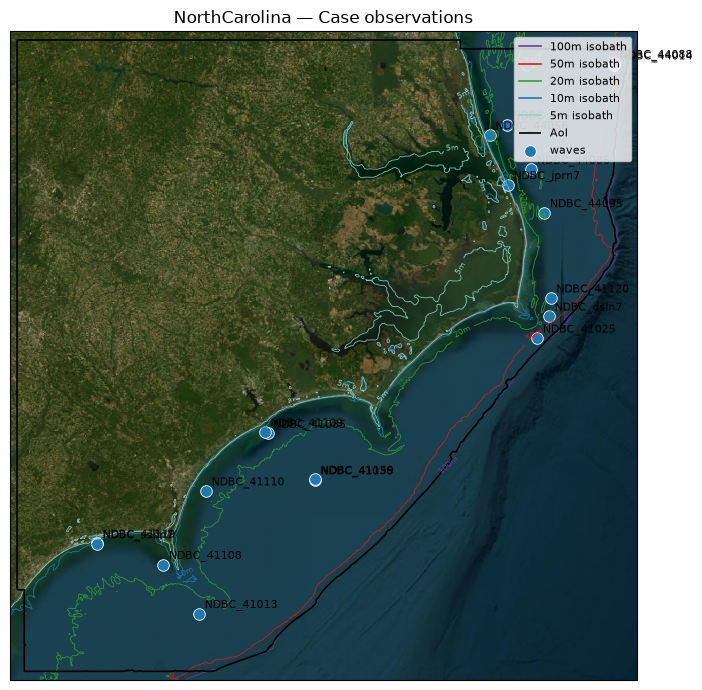

In [5]:
plot.plot_case_map(
    obs.dict_to_gdf(observations), title="Case observations", show_satellite=True
)

## Save observations JSON (GeoJSON format)

In [6]:
obs.save_geojson(feature_collection, output_path)

print(f"Wrote {len(feature_collection['features'])} feature(s) to:\n  {output_path}")

Wrote 19 feature(s) to:
  /lustre/geocean/WORK/users/javiert/projects/HyGloW/NorthCarolina/inputs/Observations/NorthCarolina_observations.json


## Update the case JSON

After saving, add or update this key in the case JSON so downstream notebooks use your new file:

```json
"onshore_waves": "inputs/Observations/<Case>_observations.json"
```

Use the exact relative path you set in `output_observations_file`.

## Processed buoy records

Notebook 10 reads `inputs/Observations/processed/<instrument_id>.nc` (hourly `hs`,
`tp`, `dir`, `spr` on `time`). They are written here from the hourly NDBC tables of
the ShoreShop pipeline (`utils/shoreshop_buoys.py`, case-only code): Hs, Tp and
mean direction to 2024, **no spreading**. The CDIP stations also publish spreading
and spectra (`bluemath_tk.waves.cdip`): not downloaded yet (notebook 11 needs them).

In [7]:
from utils import shoreshop_buoys

shoreshop_buoys.write_processed(observations, resolve("inputs/Observations/processed"))

,first,last,hours_hs,hours_dir
buoy,,,,
NDBC_41013,2003-11-11 00:00:00,2023-12-31 23:00:00,159011,154148
NDBC_41025,2003-03-28 20:00:00,2024-12-31 23:00:00,142292,74261
NDBC_41035,2005-08-01 21:00:00,2010-12-31 22:00:00,41758,37467
NDBC_41036,2006-07-06 21:00:00,2015-01-07 20:00:00,63789,62063
NDBC_41108,2013-02-07 22:00:00,2024-12-31 23:00:00,96827,96805
NDBC_41109,2012-04-16 15:00:00,2013-10-30 20:00:00,13324,13298
NDBC_41110,2008-05-07 20:00:00,2024-12-31 23:00:00,136026,135817
NDBC_41119,2019-06-17 18:00:00,2019-12-31 23:00:00,4723,4699
NDBC_41120,2021-08-02 21:00:00,2024-12-31 23:00:00,29503,29497


## Output sites on the model mesh

All output sites are built here, once, on the mesh of `simulations.model`
(`simulations.<model>.grid_file`): isobaths traced on the topobathy raster
blanked outside the mesh (`simulations.output_sites_config`), plus the buoys
just saved. Each site gets its **`mesh_depth`** (the depth the models see, used
from here on) next to its nominal depth (contour level, or the buoy's
`measured_depth`), and is kept only if it is inside the mesh and still wet at
the lowest metamodel water level (`simulations.bounds.wl[0]`, with
`simulations.min_depth`).

The table, dropped sites included, goes to `outputs/output_sites_{model}.csv`;
the metamodel cases (05) and the dynamic runs (08) read it. Rebuilding it
(`recompute=True`) invalidates runs made with the old sites.

In [8]:
from utils.geometry import buoy_depth_check, output_sites, sites_summary

sites = output_sites(recompute=True, all_sites=True)
sites_summary(sites)

INFO:hywaves.geometry:Dropped 9/4487 sites (outside the mesh, or dry at wl -1.25 m with min depth 0.10 m): 5m can_dry 9


INFO:hywaves.geometry:Output sites (snapwave): 4478 of 4487 ok -> /lustre/geocean/WORK/users/javiert/projects/HyGloW/NorthCarolina/outputs/output_sites_snapwave.csv


,sites,ok,outside_mesh,can_dry,min,p10,median,p90,max
group,,,,,,,,,
5m,342.0,333.0,0.0,9.0,1.5,4.4,5.5,6.6,8.0
8m,2854.0,2854.0,0.0,0.0,1.8,7.8,8.3,9.6,16.8
10m,406.0,406.0,0.0,0.0,8.1,9.7,10.1,10.7,13.0
20m,754.0,754.0,0.0,0.0,18.1,19.7,20.0,20.3,22.3
50m,112.0,112.0,0.0,0.0,48.8,49.5,50.0,50.3,53.6
buoy,19.0,19.0,0.0,0.0,10.7,11.6,19.4,46.5,63.0
total,4487.0,4478.0,0.0,9.0,NaN,NaN,NaN,NaN,NaN


Buoys: measured depth (station metadata) against the mesh depth. A large
difference (`flag`) points to wrong coordinates, a bank or channel the mesh
smooths out, or another vertical datum.

In [9]:
buoy_depth_check(sites)

,source_id,name,measured_depth,mesh_depth,difference,status,flag
0,buoy_NDBC_41013,Frying Pan Shoals,30.80,27.7,-3.1,ok,False
1,buoy_NDBC_41025,Diamond Shoals,61.00,63.0,2.0,ok,False
2,buoy_NDBC_41035,Onslow Bay Inner,9.70,14.0,4.3,ok,True
3,buoy_NDBC_41036,Onslow Bay Outer,NaN,29.5,NaN,ok,False
4,buoy_NDBC_41108,Wilmington Harbor (CDIP 200),12.80,14.0,1.2,ok,False
5,buoy_NDBC_41109,New River Inlet (CDIP 190),13.20,13.9,0.7,ok,False
6,buoy_NDBC_41110,Masonboro Inlet (CDIP 150),17.00,16.6,-0.4,ok,False
7,buoy_NDBC_41119,Sunset Beach (CDIP 245),13.00,10.7,-2.3,ok,False
8,buoy_NDBC_41120,Cape Hatteras East (CDIP 250),29.00,27.8,-1.2,ok,False
9,buoy_NDBC_41159,Onslow Bay Outer (CDIP 217),30.50,28.8,-1.7,ok,False


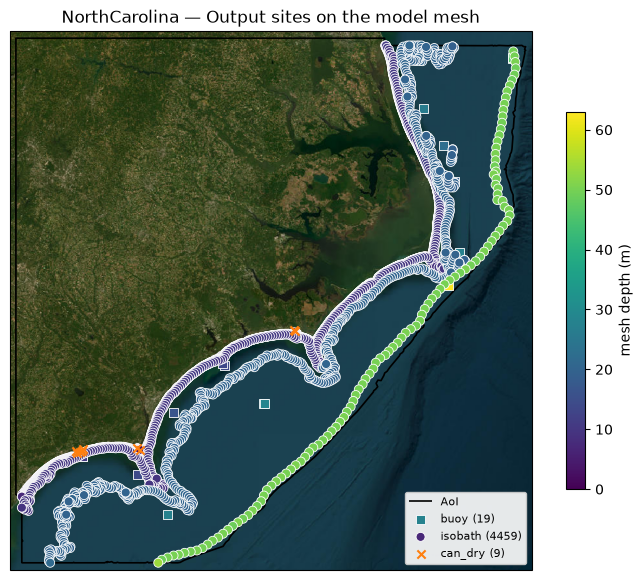

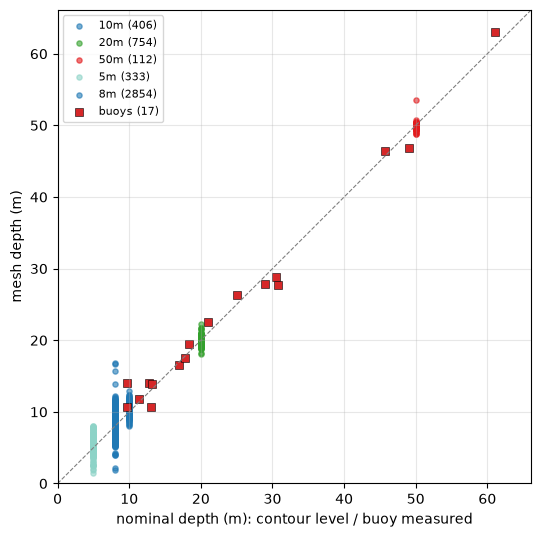

In [10]:
plot.plot_output_sites(sites, show_satellite=True)
plot.plot_site_depths(sites);